<a href="https://colab.research.google.com/github/Harsh-Raj-0223/HCL-Training/blob/main/Retailstore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving retail_sales_1_to_1000.csv to retail_sales_1_to_1000.csv
=== Q1: OVERALL KPIs (1,000 clean orders | 2025-01-03 to 2026-05-15) ===
Total Revenue: ₹29,974,603 | Total Units: 2,997 | Mean AOV: ₹29,974.60 | Median: ₹5,196.00

=== Q2: CATEGORY & PRODUCT SHARE ===
   Category  Orders  Revenue      AOV  Share_%
Accessories     489 16508516 33759.75    55.08
Electronics     511 13466087 26352.42    44.92

   Product  Orders  Units  Revenue      AOV  Share_%
  Keyboard     171    491  6243709 36512.92    20.83
Headphones     165    504  5841296 35401.79    19.49
    Laptop     154    465  5312735 34498.28    17.72
     Mouse     165    492  4424808 26817.02    14.76
    Webcam     178    558  4113442 23109.22    13.72
   Monitor     167    487  4038613 24183.31    13.47

=== Q3: BRANCH PERFORMANCE ===
     City  Orders  Revenue      AOV  Customers  Share_%
Bengaluru     224  7205516 32167.48        144    24.04
    Delhi     204  6272299 30746.56        138    20.93
Hyderabad     211  60

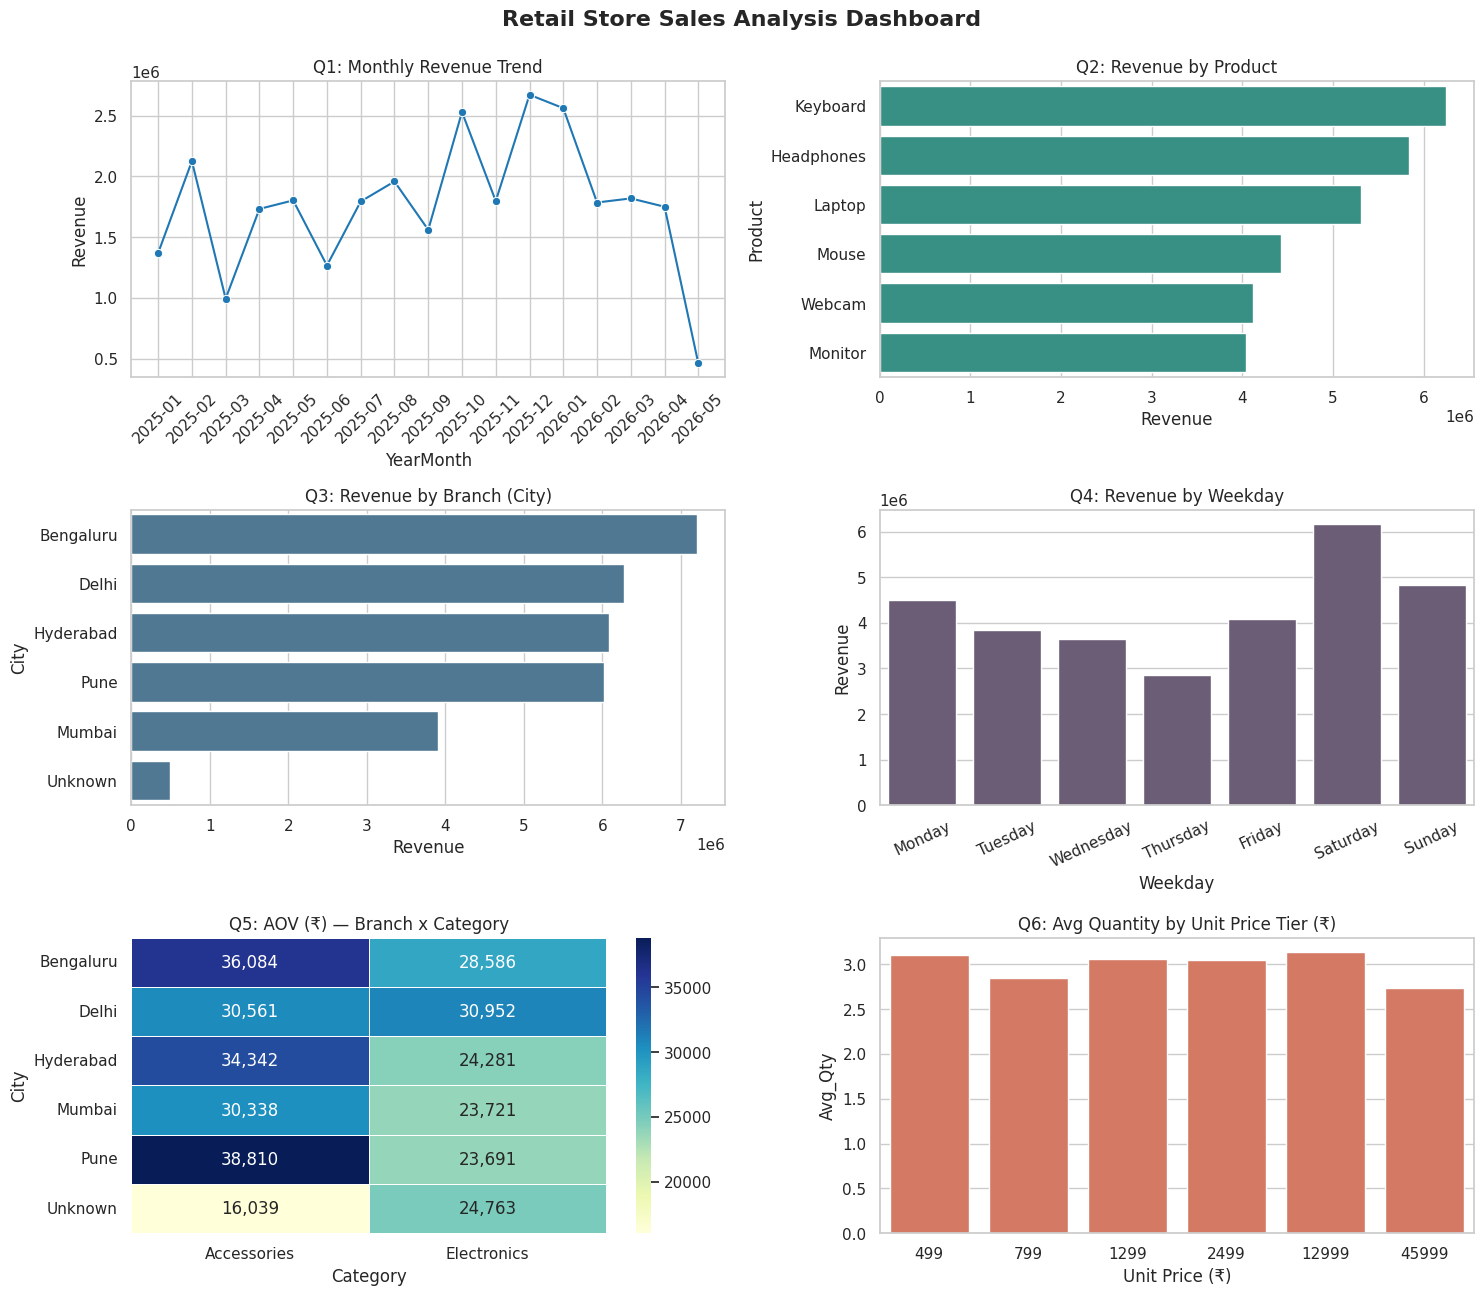


Done in 432.62 seconds.


In [2]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

t0 = time.time()
sns.set_theme(style="whitegrid")

# 1. Load dataset (auto-prompts file upload in Google Colab if CSV isn't already in workspace)
default_file = "retail_sales_1_to_1000.csv"
if os.path.exists(default_file):
    filename = default_file
else:
    from google.colab import files
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

# 2. Clean & Engineer Features
df = df.drop_duplicates().copy()
if "City" in df.columns:
    df["City"] = df["City"].fillna("Unknown")
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["YearMonth"] = df["Order_Date"].dt.to_period("M").astype(str)
df["Weekday"] = df["Order_Date"].dt.day_name()

total_rev = df["Revenue"].sum()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# 3. Compute All Summaries (Q1–Q7) in One Pass
monthly = df.groupby("YearMonth", as_index=False).agg(Orders=("Order_ID", "count"), Revenue=("Revenue", "sum"))

cat = df.groupby("Category", as_index=False).agg(Orders=("Order_ID", "count"), Revenue=("Revenue", "sum"), AOV=("Revenue", "mean")).sort_values("Revenue", ascending=False)
cat["Share_%"] = (cat["Revenue"] / total_rev * 100).round(2)

prod = df.groupby("Product", as_index=False).agg(Orders=("Order_ID", "count"), Units=("Quantity", "sum"), Revenue=("Revenue", "sum"), AOV=("Revenue", "mean")).sort_values("Revenue", ascending=False)
prod["Share_%"] = (prod["Revenue"] / total_rev * 100).round(2)

branch = df.groupby("City", as_index=False).agg(Orders=("Order_ID", "count"), Revenue=("Revenue", "sum"), AOV=("Revenue", "mean"), Customers=("Customer_ID", "nunique")).sort_values("Revenue", ascending=False)
branch["Share_%"] = (branch["Revenue"] / total_rev * 100).round(2)

wd = df.groupby("Weekday").agg(Orders=("Order_ID", "count"), Revenue=("Revenue", "sum"), AOV=("Revenue", "mean")).reindex(weekday_order).reset_index()
aov_pivot = df.pivot_table(index="City", columns="Category", values="Revenue", aggfunc="mean").round(2)

has_discount = "Discount" in df.columns
if not has_discount:
    price_tiers = df.groupby("Unit_Price", as_index=False).agg(Orders=("Order_ID", "count"), Avg_Qty=("Quantity", "mean"), Avg_Rev=("Revenue", "mean")).round(2)
    price_tiers["Price_Label"] = price_tiers["Unit_Price"].astype(str)

cust = df.groupby("Customer_ID", as_index=False).agg(Orders=("Order_ID", "count"), Units=("Quantity", "sum"), Total_Spend=("Revenue", "sum"), AOV=("Revenue", "mean")).round(2)
pay = df.groupby("Payment_Mode", as_index=False).agg(Orders=("Order_ID", "count"), Revenue=("Revenue", "sum"), AOV=("Revenue", "mean")).sort_values("Revenue", ascending=False)
pay["Share_%"] = (pay["Revenue"] / total_rev * 100).round(2)

# 4. Print Concise Report
print(f"=== Q1: OVERALL KPIs ({len(df):,} clean orders | {df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}) ===")
print(f"Total Revenue: ₹{total_rev:,.0f} | Total Units: {df['Quantity'].sum():,} | Mean AOV: ₹{df['Revenue'].mean():,.2f} | Median: ₹{df['Revenue'].median():,.2f}")

print("\n=== Q2: CATEGORY & PRODUCT SHARE ===")
print(cat.round(2).to_string(index=False))
print("\n" + prod.round(2).to_string(index=False))

print("\n=== Q3: BRANCH PERFORMANCE ===")
print(branch.round(2).to_string(index=False))

print("\n=== Q4: WEEKDAY PERFORMANCE ===")
print(wd.round(2).to_string(index=False))

print("\n=== Q5: AOV MATRIX (CITY x CATEGORY) ===")
print(aov_pivot.to_string())

if has_discount:
    print(f"\n=== Q6: DISCOUNT IMPACT ===")
    print(f"Corr(Discount, Qty): {df['Discount'].corr(df['Quantity']):.4f} | Corr(Discount, Revenue): {df['Discount'].corr(df['Revenue']):.4f}")
else:
    print(f"\n=== Q6: PRICE SENSITIVITY (No Discount column | Corr Unit_Price vs Qty = {df['Unit_Price'].corr(df['Quantity']):.4f}) ===")
    print(price_tiers.drop(columns=["Price_Label"]).to_string(index=False))

print(f"\n=== Q7: TOP 5 CUSTOMERS (Repeat Rate: {(cust['Orders'] >= 2).mean()*100:.1f}%) ===")
print("By Spend:\n" + cust.sort_values("Total_Spend", ascending=False).head(5).to_string(index=False))
print("\nBy Frequency:\n" + cust.sort_values(["Orders", "Total_Spend"], ascending=False).head(5).to_string(index=False))
print("\nPayment Modes:\n" + pay.round(2).to_string(index=False))

print("\n=== Q8: NON-DISCOUNT BUSINESS ACTIONS ===")
for action in [
    "1. Bundle high-volume Webcams/Monitors with top-revenue Keyboards & Headphones.",
    "2. Run Thursday-only perks (bonus loyalty points or free setup) to smooth the mid-week trough.",
    "3. Audit Mumbai branch volume & enforce mandatory POS City entry to eliminate 'Unknown' records.",
    "4. Launch VIP perks (extended warranty, priority support) for top repeat & high-spend customers.",
    "5. Promote UPI/Card no-cost EMI & bank perks, which deliver higher AOV than Cash."
]:
    print(action)

# 5. Render All 6 Charts Together in One Fast 3x2 Dashboard
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
fig.suptitle("Retail Store Sales Analysis Dashboard", fontsize=16, fontweight="bold", y=0.995)

sns.lineplot(data=monthly, x="YearMonth", y="Revenue", marker="o", color="#1f77b4", ax=axes[0, 0])
axes[0, 0].set_title("Q1: Monthly Revenue Trend")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.barplot(data=prod, x="Revenue", y="Product", color="#2a9d8f", ax=axes[0, 1])
axes[0, 1].set_title("Q2: Revenue by Product")

sns.barplot(data=branch, x="Revenue", y="City", color="#457b9d", ax=axes[1, 0])
axes[1, 0].set_title("Q3: Revenue by Branch (City)")

sns.barplot(data=wd, x="Weekday", y="Revenue", color="#6d597a", ax=axes[1, 1])
axes[1, 1].set_title("Q4: Revenue by Weekday")
axes[1, 1].tick_params(axis="x", rotation=25)

sns.heatmap(aov_pivot, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=0.5, ax=axes[2, 0])
axes[2, 0].set_title("Q5: AOV (₹) — Branch x Category")

if has_discount:
    sns.scatterplot(data=df, x="Discount", y="Revenue", color="#e76f51", alpha=0.6, ax=axes[2, 1])
    axes[2, 1].set_title("Q6: Discount vs. Order Revenue")
else:
    sns.barplot(data=price_tiers, x="Price_Label", y="Avg_Qty", color="#e76f51", ax=axes[2, 1])
    axes[2, 1].set_title("Q6: Avg Quantity by Unit Price Tier (₹)")
    axes[2, 1].set_xlabel("Unit Price (₹)")

plt.tight_layout()
plt.show()

print(f"\nDone in {time.time() - t0:.2f} seconds.")